# Validación temporal y actualización del valorador de VISSOTIA

Este notebook reproduce el tratamiento de la captura de DataVenues del 16 de noviembre de 2026 y evalúa el modelo entrenado con la captura de abril. Responde a tres controles metodológicos: usar datos realmente posteriores, impedir que una vivienda republicada aparezca en entrenamiento y prueba, y comparar XGBoost con una referencia sencilla que utiliza zona y superficie.

La evaluación externa se cierra antes de entrenar el modelo candidato. El nuevo artefacto se guarda como *challenger* y no sustituye al modelo vigente hasta validarlo con otra captura futura.

## 1. Configuración y fuentes

Los CSV de `bronze/` se leen sin modificarlos. Las salidas se escriben en `local_output/`, carpeta protegida frente a Git. `Días` y `Demanda` se conservan para análisis, pero no se usan como predictores del precio inicial.

In [1]:
from __future__ import annotations

import json
import platform
import sys
import unicodedata
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

PROJECT_ROOT = next(
    candidate
    for candidate in [Path.cwd(), *Path.cwd().parents]
    if (candidate / 'scripts').is_dir() and (candidate / 'data').is_dir()
)
sys.path.insert(0, str(PROJECT_ROOT / 'scripts'))

import prepare_vissotia_data as preparation
import train_vissotia_valuation as training

SNAPSHOT_DIR = PROJECT_ROOT / 'data/snapshots/datavenues/2026-11-16'
BRONZE_DIR = SNAPSHOT_DIR / 'bronze'
OUTPUT_DIR = SNAPSHOT_DIR / 'local_output'
APRIL_GOLD_PATH = PROJECT_ROOT / 'data/entregas/02/local_output/vissotia_valoracion_gold.csv'
CHAMPION_PATH = PROJECT_ROOT / 'data/entregas/03/local_output/modelo_valoracion_inicial_xgboost.joblib'
EXTRACTION_DATE = '2026-11-16'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Proyecto:', PROJECT_ROOT.name)
print('Captura:', SNAPSHOT_DIR.name)

Proyecto: TFM_Evolve_Abril_2026
Captura: 2026-11-16


## 2. Carga y validación estructural

Se exige que los ocho CSV tengan las mismas columnas y el mismo orden. Bilbao se conserva aunque proceda de Idealista porque ofrece mayor cobertura en ese municipio. La única observación cuyo municipio es Arrigorriaga se elimina aquí, no en Bronze.

In [2]:
CITY_BY_FOLDER = {
    'acoruña': 'A Coruña',
    'bilbao': 'Bilbao',
    'cordoba': 'Córdoba',
    'cuenca': 'Cuenca',
    'granada': 'Granada',
    'madrid': 'Madrid',
    'sevilla': 'Sevilla',
    'valencia': 'Valencia',
}

frames = []
inventory_rows = []
reference_header = None
arrigorriaga_removed = pd.DataFrame()

for path in sorted(BRONZE_DIR.rglob('*.csv')):
    folder = unicodedata.normalize('NFC', path.parent.name)
    city = CITY_BY_FOLDER[folder]
    raw = pd.read_csv(path)
    header = raw.columns.tolist()
    if reference_header is None:
        reference_header = header
    if header != reference_header:
        raise ValueError(f'Esquema distinto en {path.name}')

    source_tokens = sorted({
        token.strip()
        for value in raw['Fuente'].dropna().astype(str)
        for token in value.split(',')
        if token.strip()
    })
    original_rows = len(raw)
    raw.columns = [preparation.normalize_column(column) for column in raw.columns]
    raw['origen_dataset'] = city
    raw['_source_row_number'] = np.arange(len(raw), dtype=int)

    if city == 'Bilbao':
        is_bilbao = raw['municipio'].astype('string').str.strip().str.casefold().eq('bilbao')
        arrigorriaga_removed = raw.loc[~is_bilbao].copy()
        if len(arrigorriaga_removed) != 1 or arrigorriaga_removed['municipio'].iloc[0] != 'Arrigorriaga':
            raise ValueError('El control geográfico de Bilbao no coincide con lo documentado')
        raw = raw.loc[is_bilbao].copy()

    inventory_rows.append({
        'ciudad': city,
        'archivo': path.name,
        'portal_observado': ', '.join(source_tokens),
        'filas_originales': original_rows,
        'filas_utilizadas': len(raw),
        'columnas': len(header),
    })
    frames.append(raw)

inventory = pd.DataFrame(inventory_rows)
bronze_working = pd.concat(frames, ignore_index=True)
display(inventory)
print('Esquema común:', len(reference_header), 'columnas')
print('Arrigorriaga eliminado en tratamiento:', len(arrigorriaga_removed))

,ciudad,archivo,portal_observado,filas_originales,filas_utilizadas,columnas
0,A Coruña,datavenues_a_coruna_fotocasa_2026-11-16.csv,Fotocasa,507,507,41
1,Bilbao,datavenues_bilbao_2026-11-16.csv,idealista,1271,1270,41
2,Córdoba,datavenues_cordoba_fotocasa_2026-11-16.csv,Fotocasa,2000,2000,41
3,Cuenca,dataVenues_cuenca_2026-11-16.csv,Fotocasa,189,189,41
4,Granada,dataVenues_granada_2026-11-16.csv,Fotocasa,1540,1540,41
5,Madrid,dataVenues_madrid_2026-11-16.csv,Fotocasa,2000,2000,41
6,Sevilla,dataVenues_sevilla_2026-11-16.csv,Fotocasa,2000,2000,41
7,Valencia,dataVenues_valencia_2026-11-16.csv,Fotocasa,2000,2000,41


Esquema común: 41 columnas
Arrigorriaga eliminado en tratamiento: 1


## 3. Preparación Silver y Gold

Se reutilizan las reglas auditadas de la Entrega 2: normalización de tipos, deduplicación por referencia o URL, minimización de datos, controles de precio, superficie, dormitorios y baños, y generación de un identificador técnico que no depende del precio.

In [3]:
november_silver, quality_report = preparation.build_silver(
    bronze_working, extraction_date=EXTRACTION_DATE
)
november_gold = preparation.build_gold(november_silver)

quality_summary = pd.DataFrame({
    'control': [
        'Filas originales',
        'Arrigorriaga eliminado',
        'Duplicados eliminados',
        'Filas descartadas por calidad',
        'Filas Gold de noviembre',
    ],
    'filas': [
        int(inventory['filas_originales'].sum()),
        len(arrigorriaga_removed),
        quality_report['duplicados_eliminados'],
        quality_report['filas_tras_deduplicacion'] - quality_report['filas_tras_filtros_calidad'],
        len(november_gold),
    ],
})
display(quality_summary)
display(november_gold['origen_dataset'].value_counts().rename_axis('ciudad').reset_index(name='filas'))

,control,filas
0,Filas originales,11507
1,Arrigorriaga eliminado,1
2,Duplicados eliminados,206
3,Filas descartadas por calidad,3
4,Filas Gold de noviembre,11297


,ciudad,filas
0,Madrid,1986
1,Valencia,1984
2,Córdoba,1949
3,Sevilla,1886
4,Granada,1529
5,Bilbao,1270
6,A Coruña,504
7,Cuenca,189


## 4. Control de viviendas republicadas

La prueba externa excluye únicamente coincidencias exactas de `id_observacion`, identificador técnico derivado de la referencia o URL del anuncio. No se consideran duplicadas dos viviendas por compartir municipio, coordenadas aproximadas, superficie, dormitorios y baños: en un mismo edificio pueden existir inmuebles distintos con características casi idénticas. Si una republicación cambia tanto de referencia como de URL, no puede identificarse de forma concluyente con el Gold minimizado y se conserva.

In [4]:
april_gold_raw = pd.read_csv(APRIL_GOLD_PATH)
exact_match = november_gold['id_observacion'].isin(set(april_gold_raw['id_observacion']))
republication_mask = exact_match
republication_exclusions = november_gold.loc[republication_mask, [
    'id_observacion', 'origen_dataset', 'fecha_publicacion'
]].copy()
republication_exclusions['motivo'] = 'id_observacion_exacto'
external_test_gold = november_gold.loc[~republication_mask].reset_index(drop=True)

republication_summary = pd.DataFrame({
    'control': ['Coincidencias exactas excluidas', 'Test externo final'],
    'filas': [republication_mask.sum(), len(external_test_gold)],
})
display(republication_summary)
display(pd.crosstab(november_gold['origen_dataset'], republication_mask, colnames=['excluida_por_republicación']))

,control,filas
0,Coincidencias exactas excluidas,159
1,Test externo final,11138


excluida_por_republicación,False,True
origen_dataset,,
A Coruña,504,0
Bilbao,1270,0
Cuenca,189,0
Córdoba,1808,141
Granada,1529,0
Madrid,1979,7
Sevilla,1875,11
Valencia,1984,0


## 5. Champion frente al baseline de zona y superficie

El baseline aprende únicamente de abril la mediana del precio por metro cuadrado. Aplica una jerarquía de barrio, código postal, distrito y municipio, siempre que existan al menos 10 testigos; si no hay cobertura, utiliza la mediana global. Así se compara XGBoost con una regla transparente que también conoce la ubicación, sin utilizar información de noviembre para calcular sus referencias.

In [5]:
def prepare_model_frame(frame: pd.DataFrame) -> pd.DataFrame:
    result = frame.copy()
    result[training.DATE_COLUMN] = pd.to_datetime(result[training.DATE_COLUMN], errors='coerce')
    result[training.EXTRACTION_DATE_COLUMN] = pd.to_datetime(
        result[training.EXTRACTION_DATE_COLUMN], errors='coerce'
    )
    if result[[training.DATE_COLUMN, training.EXTRACTION_DATE_COLUMN]].isna().any().any():
        raise ValueError('Existen fechas no válidas')
    if (result[training.DATE_COLUMN] > result[training.EXTRACTION_DATE_COLUMN]).any():
        raise ValueError('Existen publicaciones posteriores a la extracción')
    result['codigo_postal'] = result['codigo_postal'].map(training.normalize_postcode)
    result['anio_mercado'] = result[training.DATE_COLUMN].dt.year.astype(float)
    result['mes_mercado'] = result[training.DATE_COLUMN].dt.month.astype('Int64').astype('string')
    for column in training.CATEGORICAL_FEATURES:
        result[column] = result[column].astype(object).where(result[column].notna(), np.nan)
    return result

def zone_surface_baseline(
    train: pd.DataFrame, test: pd.DataFrame, minimum_witnesses: int = 10
) -> tuple[pd.Series, pd.Series]:
    reference = train.copy()
    reference['precio_m2_referencia'] = (
        reference[training.TARGET] / reference['superficie_m2']
    )
    predicted_ppm2 = pd.Series(np.nan, index=test.index, dtype=float)
    level_used = pd.Series('global', index=test.index, dtype='string')
    hierarchy = [
        (['municipio', 'barrio'], 'barrio'),
        (['municipio', 'codigo_postal'], 'codigo_postal'),
        (['municipio', 'distrito'], 'distrito'),
        (['municipio'], 'municipio'),
    ]
    for keys, label in hierarchy:
        stats = (
            reference.groupby(keys, dropna=False)['precio_m2_referencia']
            .agg(['median', 'count'])
            .reset_index()
        )
        stats = stats.loc[stats['count'] >= minimum_witnesses, keys + ['median']]
        stats = stats.rename(columns={'median': 'candidate_ppm2'})
        candidates = test[keys].merge(stats, on=keys, how='left')['candidate_ppm2'].to_numpy()
        use_candidate = predicted_ppm2.isna() & pd.notna(candidates)
        predicted_ppm2.loc[use_candidate] = candidates[use_candidate]
        level_used.loc[use_candidate] = label
    predicted_ppm2 = predicted_ppm2.fillna(reference['precio_m2_referencia'].median())
    prediction = predicted_ppm2 * pd.to_numeric(test['superficie_m2'], errors='coerce')
    return prediction.clip(lower=0), level_used

def regression_metrics(frame: pd.DataFrame, prediction_column: str) -> dict[str, float]:
    actual = frame[training.TARGET].astype(float)
    predicted = frame[prediction_column].astype(float).clip(lower=0)
    return {
        'n': int(len(frame)),
        'mae_eur': float(mean_absolute_error(actual, predicted)),
        'rmse_eur': float(np.sqrt(mean_squared_error(actual, predicted))),
        'r2': float(r2_score(actual, predicted)) if len(frame) > 1 else np.nan,
        'mape_pct': float((np.abs((actual - predicted) / actual) * 100).mean()),
    }

In [6]:
april_model_frame = training.load_gold(APRIL_GOLD_PATH)
external_model_frame = prepare_model_frame(external_test_gold)
champion = joblib.load(CHAMPION_PATH)

predictions = external_model_frame[[
    'id_observacion', 'fecha_publicacion', 'origen_dataset', training.TARGET
]].copy()
predictions['pred_xgboost_champion'] = np.maximum(
    champion.predict(training.feature_frame(external_model_frame)), 0
)
baseline_prediction, baseline_level = zone_surface_baseline(
    april_model_frame, external_model_frame
)
predictions['pred_baseline_zona_superficie'] = baseline_prediction.to_numpy()
predictions['nivel_baseline'] = baseline_level.to_numpy()
known_cities = set(april_model_frame['origen_dataset'].dropna().unique())
predictions['cobertura_geografica'] = np.where(
    predictions['origen_dataset'].isin(known_cities),
    'ciudades_conocidas',
    'ciudades_nuevas',
)

metric_rows = []
for scope, subset in [('total', predictions), *list(predictions.groupby('cobertura_geografica'))]:
    for model_name, column in {
        'XGBoost champion': 'pred_xgboost_champion',
        'Baseline zona + superficie': 'pred_baseline_zona_superficie',
    }.items():
        metric_rows.append({
            'ambito': scope, 'modelo': model_name,
            **regression_metrics(subset, column),
        })
external_metrics = pd.DataFrame(metric_rows)
display(external_metrics.round({'mae_eur': 0, 'rmse_eur': 0, 'r2': 3, 'mape_pct': 2}))
display(predictions['nivel_baseline'].value_counts().rename_axis('nivel').reset_index(name='filas'))

,ambito,modelo,n,mae_eur,rmse_eur,r2,mape_pct
0,total,XGBoost champion,11138,102260.0,162748.0,0.537,31.48
1,total,Baseline zona + superficie,11138,95156.0,150025.0,0.606,32.12
2,ciudades_conocidas,XGBoost champion,5662,61568.0,102658.0,0.839,22.58
3,ciudades_conocidas,Baseline zona + superficie,5662,69259.0,113028.0,0.805,27.12
4,ciudades_nuevas,XGBoost champion,5476,144334.0,207309.0,0.097,40.68
5,ciudades_nuevas,Baseline zona + superficie,5476,121932.0,180473.0,0.316,37.30


,nivel,filas
0,global,5476
1,barrio,5274
2,codigo_postal,354
3,distrito,34


## 6. Error por ciudad

Las ciudades presentes en abril miden desplazamiento temporal. Las ciudades incorporadas por primera vez miden extrapolación geográfica y deben analizarse por separado. En Bilbao, además, ciudad y portal están confundidos porque sus anuncios proceden de Idealista.

,ciudad,modelo,cobertura_geografica,n,mae_eur,rmse_eur,r2,mape_pct
0,A Coruña,XGBoost champion,ciudades_nuevas,504,183162.0,223932.0,0.051,76.60
1,A Coruña,Baseline zona + superficie,ciudades_nuevas,504,129747.0,191087.0,0.309,38.49
2,Bilbao,XGBoost champion,ciudades_nuevas,1270,110742.0,164591.0,0.542,26.89
3,Bilbao,Baseline zona + superficie,ciudades_nuevas,1270,174656.0,237206.0,0.050,35.67
4,Cuenca,XGBoost champion,ciudades_nuevas,189,72233.0,121335.0,0.350,56.86
5,Cuenca,Baseline zona + superficie,ciudades_nuevas,189,126681.0,166504.0,-0.224,106.31
6,Córdoba,XGBoost champion,ciudades_conocidas,1808,41884.0,63140.0,0.736,21.46
7,Córdoba,Baseline zona + superficie,ciudades_conocidas,1808,52077.0,76277.0,0.614,27.35
8,Granada,XGBoost champion,ciudades_nuevas,1529,156160.0,214710.0,-0.383,46.08
9,Granada,Baseline zona + superficie,ciudades_nuevas,1529,86669.0,125717.0,0.526,41.70


,tramo_precio,modelo,n,mae_eur,rmse_eur,r2,mape_pct
0,Hasta 150 mil,XGBoost champion,1954,40606.0,70534.0,-3.278,47.27
1,Hasta 150 mil,Baseline zona + superficie,1954,53628.0,89351.0,-5.865,63.49
2,150 a 300 mil,XGBoost champion,4392,58389.0,86576.0,-2.927,25.88
3,150 a 300 mil,Baseline zona + superficie,4392,53551.0,83618.0,-2.664,24.06
4,300 a 600 mil,XGBoost champion,3460,122007.0,153342.0,-2.545,28.87
5,300 a 600 mil,Baseline zona + superficie,3460,107768.0,136841.0,-1.823,25.40
6,Más de 600 mil,XGBoost champion,1332,286066.0,358313.0,-1.840,33.55
7,Más de 600 mil,Baseline zona + superficie,1332,260498.0,323725.0,-1.318,30.19


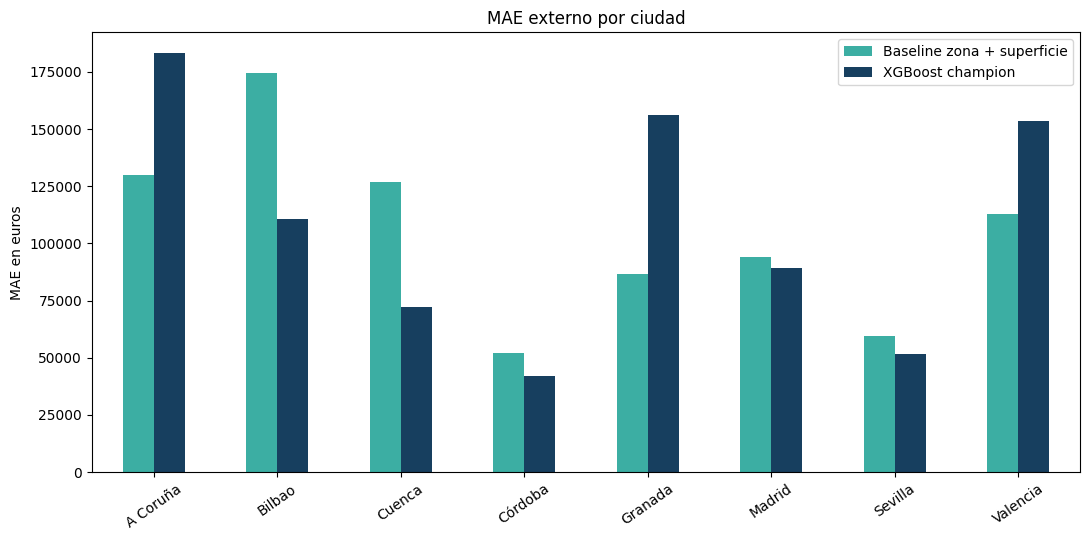

In [7]:
city_rows = []
for city, subset in predictions.groupby('origen_dataset'):
    for model_name, column in {
        'XGBoost champion': 'pred_xgboost_champion',
        'Baseline zona + superficie': 'pred_baseline_zona_superficie',
    }.items():
        city_rows.append({
            'ciudad': city, 'modelo': model_name,
            'cobertura_geografica': subset['cobertura_geografica'].iloc[0],
            **regression_metrics(subset, column),
        })
metrics_by_city = pd.DataFrame(city_rows)
display(metrics_by_city.round({'mae_eur': 0, 'rmse_eur': 0, 'r2': 3, 'mape_pct': 2}))

price_band_work = predictions.copy()
price_band_work['tramo_precio'] = pd.cut(
    price_band_work[training.TARGET],
    bins=[0, 150_000, 300_000, 600_000, np.inf],
    labels=['Hasta 150 mil', '150 a 300 mil', '300 a 600 mil', 'Más de 600 mil'],
    include_lowest=True,
)
band_rows = []
for band, subset in price_band_work.groupby('tramo_precio', observed=True):
    for model_name, column in {
        'XGBoost champion': 'pred_xgboost_champion',
        'Baseline zona + superficie': 'pred_baseline_zona_superficie',
    }.items():
        band_rows.append({
            'tramo_precio': str(band), 'modelo': model_name,
            **regression_metrics(subset, column),
        })
metrics_by_price_band = pd.DataFrame(band_rows)
display(metrics_by_price_band.round({'mae_eur': 0, 'rmse_eur': 0, 'r2': 3, 'mape_pct': 2}))

plot_data = metrics_by_city.pivot(index='ciudad', columns='modelo', values='mae_eur')
ax = plot_data.plot(kind='bar', figsize=(11, 5.5), color=['#3CAEA3', '#173F5F'])
ax.set_title('MAE externo por ciudad')
ax.set_xlabel('')
ax.set_ylabel('MAE en euros')
ax.tick_params(axis='x', rotation=35)
ax.legend(title='')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'comparacion_externa_mae_por_ciudad.png', dpi=180)
plt.show()

## 7. Sensibilidad a valores atípicos

Para comprobar si la ventaja del baseline en las ciudades nuevas se debe únicamente a anuncios extremos, se repite la comparación después de excluir valores atípicos mediante la regla de 1,5 veces el rango intercuartílico. El filtro se calcula por ciudad y utiliza solo el precio observado o el precio por metro cuadrado, nunca el error de un modelo.

Este análisis es una prueba de sensibilidad. No modifica el Gold, no elimina observaciones del entrenamiento del challenger y no sustituye los controles de calidad documentados.


In [8]:
outlier_work = predictions.merge(
    external_model_frame[['id_observacion', 'superficie_m2']],
    on='id_observacion', how='left', validate='one_to_one'
)
outlier_work['precio_m2_observado'] = (
    outlier_work[training.TARGET] / outlier_work['superficie_m2']
)
new_city_work = outlier_work.loc[
    outlier_work['cobertura_geografica'].eq('ciudades_nuevas')
].copy()

def iqr_outlier_mask(frame: pd.DataFrame, column: str) -> pd.Series:
    grouped = frame.groupby('origen_dataset')[column]
    q1 = grouped.transform(lambda values: values.quantile(0.25))
    q3 = grouped.transform(lambda values: values.quantile(0.75))
    iqr = q3 - q1
    return (frame[column] < q1 - 1.5 * iqr) | (frame[column] > q3 + 1.5 * iqr)

new_city_work['outlier_precio_m2_iqr'] = iqr_outlier_mask(
    new_city_work, 'precio_m2_observado'
)
new_city_work['outlier_precio_iqr'] = iqr_outlier_mask(
    new_city_work, training.TARGET
)

outlier_scopes = {
    'Sin filtro': new_city_work,
    'Sin outliers de precio/m2 por ciudad': new_city_work.loc[
        ~new_city_work['outlier_precio_m2_iqr']
    ],
    'Sin outliers de precio total por ciudad': new_city_work.loc[
        ~new_city_work['outlier_precio_iqr']
    ],
}
outlier_sensitivity_rows = []
for scope, subset in outlier_scopes.items():
    for model_name, column in {
        'XGBoost champion': 'pred_xgboost_champion',
        'Baseline zona + superficie': 'pred_baseline_zona_superficie',
    }.items():
        outlier_sensitivity_rows.append({
            'filtro': scope,
            'modelo': model_name,
            'observaciones': int(len(subset)),
            'observaciones_excluidas': int(len(new_city_work) - len(subset)),
            **regression_metrics(subset, column),
        })
outlier_sensitivity = pd.DataFrame(outlier_sensitivity_rows)

city_outlier_rows = []
for city, city_subset in new_city_work.groupby('origen_dataset'):
    clean_subset = city_subset.loc[~city_subset['outlier_precio_m2_iqr']]
    for model_name, column in {
        'XGBoost champion': 'pred_xgboost_champion',
        'Baseline zona + superficie': 'pred_baseline_zona_superficie',
    }.items():
        city_outlier_rows.append({
            'ciudad': city,
            'modelo': model_name,
            'observaciones_originales': int(len(city_subset)),
            'outliers_precio_m2_excluidos': int(city_subset['outlier_precio_m2_iqr'].sum()),
            **regression_metrics(clean_subset, column),
        })
outlier_sensitivity_by_city = pd.DataFrame(city_outlier_rows)

display(outlier_sensitivity.round({'mae_eur': 0, 'rmse_eur': 0, 'r2': 3, 'mape_pct': 2}))
display(outlier_sensitivity_by_city.round({'mae_eur': 0, 'rmse_eur': 0, 'r2': 3, 'mape_pct': 2}))
display(
    new_city_work['nivel_baseline']
    .value_counts(dropna=False)
    .rename_axis('nivel_baseline_ciudades_nuevas')
    .reset_index(name='observaciones')
)


,filtro,modelo,observaciones,observaciones_excluidas,n,mae_eur,rmse_eur,r2,mape_pct
0,Sin filtro,XGBoost champion,5476,0,5476,144334.0,207309.0,0.097,40.68
1,Sin filtro,Baseline zona + superficie,5476,0,5476,121932.0,180473.0,0.316,37.30
2,Sin outliers de precio/m2 por ciudad,XGBoost champion,5321,155,5321,135175.0,190384.0,0.122,40.04
3,Sin outliers de precio/m2 por ciudad,Baseline zona + superficie,5321,155,5321,111727.0,159788.0,0.382,36.42
4,Sin outliers de precio total por ciudad,XGBoost champion,5170,306,5170,120110.0,158194.0,0.063,39.58
5,Sin outliers de precio total por ciudad,Baseline zona + superficie,5170,306,5170,104648.0,146714.0,0.194,37.01


,ciudad,modelo,observaciones_originales,outliers_precio_m2_excluidos,n,mae_eur,rmse_eur,r2,mape_pct
0,A Coruña,XGBoost champion,504,9,495,180763.0,221236.0,-0.074,77.38
1,A Coruña,Baseline zona + superficie,504,9,495,120463.0,170647.0,0.361,37.99
2,Bilbao,XGBoost champion,1270,39,1231,100570.0,143324.0,0.611,26.20
3,Bilbao,Baseline zona + superficie,1270,39,1231,162067.0,214658.0,0.126,34.62
4,Cuenca,XGBoost champion,189,3,186,68970.0,114411.0,0.366,56.94
5,Cuenca,Baseline zona + superficie,189,3,186,125613.0,165720.0,-0.331,107.34
6,Granada,XGBoost champion,1529,29,1500,150671.0,204259.0,-0.376,45.63
7,Granada,Baseline zona + superficie,1529,29,1500,81919.0,114930.0,0.565,41.46
8,Valencia,XGBoost champion,1984,75,1909,139943.0,202569.0,-0.133,33.24
9,Valencia,Baseline zona + superficie,1984,75,1909,99070.0,144390.0,0.425,26.30


,nivel_baseline_ciudades_nuevas,observaciones
0,global,5476


## 8. Entrenamiento del modelo candidato

Después de guardar la evaluación externa, se combinan abril y noviembre. Cuando el identificador técnico coincide exactamente, se elimina la versión de abril y se conserva la observación más reciente. Las viviendas solo similares se mantienen. El candidato utiliza la misma arquitectura y las mismas variables autorizadas que el champion.

In [9]:
november_ids = set(november_gold['id_observacion'])
april_replaced = april_gold_raw['id_observacion'].isin(november_ids)
april_for_candidate = april_gold_raw.loc[~april_replaced].copy()
combined_gold = pd.concat([april_for_candidate, november_gold], ignore_index=True)
combined_gold = combined_gold.drop_duplicates('id_observacion', keep='last')
combined_model_frame = prepare_model_frame(combined_gold)

challenger = training.make_models()['XGBoost']
challenger.fit(
    training.feature_frame(combined_model_frame),
    combined_model_frame[training.TARGET],
)
challenger_path = OUTPUT_DIR / 'modelo_valoracion_challenger_2026-11-16.joblib'
joblib.dump(challenger, challenger_path)

candidate_summary = pd.DataFrame({
    'control': [
        'Gold de abril', 'Filas de abril sustituidas',
        'Gold de noviembre', 'Entrenamiento combinado',
    ],
    'filas': [
        len(april_gold_raw), int(april_replaced.sum()),
        len(november_gold), len(combined_model_frame),
    ],
})
display(candidate_summary)
display(combined_model_frame['origen_dataset'].value_counts().rename_axis('ciudad').reset_index(name='filas'))
print('Challenger guardado en:', challenger_path.name)

,control,filas
0,Gold de abril,5605
1,Filas de abril sustituidas,159
2,Gold de noviembre,11297
3,Entrenamiento combinado,16743


,ciudad,filas
0,Madrid,3927
1,Córdoba,3671
2,Sevilla,3669
3,Valencia,1984
4,Granada,1529
5,Bilbao,1270
6,A Coruña,504
7,Cuenca,189


Challenger guardado en: modelo_valoracion_challenger_2026-11-16.joblib


## 9. Artefactos y decisión MLOps

El notebook guarda resultados sin datos personales y un informe de trazabilidad. El modelo actualizado queda en estado `challenger_not_promoted`: entrenarlo con noviembre impide volver a utilizar noviembre como prueba independiente. La promoción exige una captura futura o un conjunto de cierre que el candidato no haya visto.

In [10]:
november_gold.to_csv(OUTPUT_DIR / 'vissotia_valoracion_gold_2026-11-16.csv', index=False)
republication_exclusions.to_csv(OUTPUT_DIR / 'republicaciones_excluidas_test.csv', index=False)
predictions.to_csv(OUTPUT_DIR / 'predicciones_test_externo.csv', index=False)
external_metrics.to_csv(OUTPUT_DIR / 'metricas_test_externo.csv', index=False)
metrics_by_city.to_csv(OUTPUT_DIR / 'metricas_test_externo_por_ciudad.csv', index=False)
metrics_by_price_band.to_csv(OUTPUT_DIR / 'metricas_test_externo_por_tramo_precio.csv', index=False)
outlier_sensitivity.to_csv(OUTPUT_DIR / 'sensibilidad_outliers_ciudades_nuevas.csv', index=False)
outlier_sensitivity_by_city.to_csv(OUTPUT_DIR / 'sensibilidad_outliers_por_ciudad.csv', index=False)

report = {
    'experiment': 'validacion_externa_2026-11-16_y_challenger',
    'april_rows': int(len(april_gold_raw)),
    'november_rows_after_quality': int(len(november_gold)),
    'arrigorriaga_removed': int(len(arrigorriaga_removed)),
    'republications_excluded_from_external_test': int(republication_mask.sum()),
    'republication_matching_policy': 'coincidencia_exacta_id_observacion',
    'external_test_rows': int(len(external_test_gold)),
    'external_metrics': external_metrics.to_dict(orient='records'),
    'metrics_by_city': metrics_by_city.to_dict(orient='records'),
    'metrics_by_price_band': metrics_by_price_band.to_dict(orient='records'),
    'outlier_sensitivity_new_cities': outlier_sensitivity.to_dict(orient='records'),
    'outlier_sensitivity_by_city': outlier_sensitivity_by_city.to_dict(orient='records'),
    'baseline': {
        'method': 'mediana_precio_m2_jerarquica',
        'hierarchy': ['barrio', 'codigo_postal', 'distrito', 'municipio', 'global'],
        'minimum_witnesses': 10,
        'trained_only_with_april': True,
    },
    'challenger': {
        'status': 'challenger_not_promoted',
        'training_rows': int(len(combined_model_frame)),
        'april_rows_replaced_by_november': int(april_replaced.sum()),
        'artifact': challenger_path.name,
        'promotion_requirement': 'Validación con una captura futura no utilizada en entrenamiento',
    },
    'excluded_features': {
        'post_publication': training.EXCLUDED_POST_PUBLICATION,
        'unverified_context': training.EXCLUDED_UNVERIFIED_CONTEXT,
    },
    'versions': {
        'python': platform.python_version(),
        'pandas': pd.__version__,
        'numpy': np.__version__,
        'scikit_learn': sklearn.__version__,
        'xgboost': xgboost.__version__,
        'joblib': joblib.__version__,
    },
    'random_state': training.RANDOM_STATE,
}
(OUTPUT_DIR / 'external_validation_report.json').write_text(
    json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8'
)

print('Evaluación externa guardada antes del reentrenamiento.')
print('Estado del nuevo modelo:', report['challenger']['status'])

Evaluación externa guardada antes del reentrenamiento.
Estado del nuevo modelo: challenger_not_promoted


## Conclusiones que deben interpretarse al ejecutar

- La comparación principal del champion debe leerse en las ciudades ya presentes en abril: Madrid, Sevilla y Córdoba.
- A Coruña, Bilbao, Cuenca, Granada y Valencia evalúan extrapolación geográfica, no solo cambio temporal.
- Cuando el baseline recurre al nivel global, no conoce realmente la zona; el nivel aplicado queda registrado por observación.
- Bilbao combina una ciudad nueva con un portal distinto, por lo que no permite separar ambos efectos.
- El challenger incorpora las nuevas ciudades, pero necesita una captura posterior antes de poder convertirse en champion.- La exclusión de valores atípicos por ciudad no invierte la comparación global en las ciudades nuevas; la pérdida del champion responde principalmente al cambio de distribución y a la extrapolación geográfica.
